In [1]:

from pathlib import Path
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")

# Project paths
BASE_DIR = Path.cwd().parent

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

DATA_DIR = BASE_DIR / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

# Create directories if needed
for folder in [RAW_DIR, PROCESSED_DIR, RESULTS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Notebook 07 Setup Completed!")
print("Project Root:", BASE_DIR)
print("Raw Data Exists:", RAW_DIR.exists())
print("Processed Data Exists:", PROCESSED_DIR.exists())
print("Results Data Exists:", RESULTS_DIR.exists())


Notebook 07 Setup Completed!
Project Root: C:\Users\Victus\OneDrive\Desktop\EventEcho_streamlit
Raw Data Exists: True
Processed Data Exists: True
Results Data Exists: True


In [4]:

print("PROCESSED DIRECTORY FILES:")
for file in sorted(PROCESSED_DIR.glob("*.csv")):
    print(file.name)

print("\nRESULTS DIRECTORY FILES:")
for file in sorted(RESULTS_DIR.glob("*.csv")):
    print(file.name)


PROCESSED DIRECTORY FILES:
bertopic_topic_assignments.csv
bertopic_topic_info.csv
finbert_sentiment_results.csv
integrated_nlp_features.csv
minilm_headline_mapping.csv
pilot_closing_prices.csv
pilot_daily_returns.csv
spacy_filtered_entities.csv
spacy_raw_entities.csv
unique_nlp_headlines.csv

RESULTS DIRECTORY FILES:
aar_caar_results.csv
abnormal_returns.csv
advanced_model_validation.csv
company_car_comparison.csv
company_sentiment_car_comparison.csv
event_car_summary.csv
event_news_mapping_template.csv
event_window_car_matrix.csv
final_event_news_mapping.csv
final_event_study_summary.csv
initial_data_audit.csv
integrated_event_sentiment_car.csv
market_model_results.csv
pilot_events.csv
t_test_results.csv
volatility_comparison.csv
volatility_results.csv
wilcoxon_results.csv


In [5]:

# Load existing event datasets from correct locations

pilot_events = pd.read_csv(
    RESULTS_DIR / "pilot_events.csv"
)

event_car_summary = pd.read_csv(
    RESULTS_DIR / "event_car_summary.csv"
)

event_news_mapping = pd.read_csv(
    RESULTS_DIR / "final_event_news_mapping.csv"
)

print("PILOT EVENTS")
print("Shape:", pilot_events.shape)
display(pilot_events.head())

print("\nEVENT CAR SUMMARY")
print("Shape:", event_car_summary.shape)
display(event_car_summary.head())

print("\nEVENT NEWS MAPPING")
print("Shape:", event_news_mapping.shape)
display(event_news_mapping.head())


PILOT EVENTS
Shape: (8, 11)


,event_id,company,event_date,event_category,headline,source,source_url,reaction_date,available_estimation_days,announcement_timing,verification_status
0,EV001,AAPL,2025-01-30,Quarterly Earnings,Apple reports first quarter results,Apple IR,https://www.apple.com/newsroom/2025/01/apple-r...,2025-01-31,100,After market close,Official source verified
1,EV002,AAPL,2025-05-01,Quarterly Earnings,Apple reports second quarter results,Apple IR,https://www.apple.com/newsroom/2025/05/apple-r...,2025-05-02,100,After market close,Official source verified
2,EV003,AAPL,2025-07-31,Quarterly Earnings,Apple reports third quarter results,Apple IR,https://www.apple.com/in/newsroom/2025/07/appl...,2025-08-01,100,After market close,Official source verified
3,EV004,MSFT,2025-01-29,Quarterly Earnings,Microsoft FY2025 Q2 earnings,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-01-30,100,After market close,Official source verified
4,EV005,MSFT,2025-04-30,Quarterly Earnings,Microsoft FY2025 Q3 earnings,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-05-01,100,After market close,Official source verified



EVENT CAR SUMMARY
Shape: (8, 6)


,event_id,company,total_CAR,average_AR,max_CAR,min_CAR
0,EV001,AAPL,-0.737394,-0.035114,-0.737394,-8.933771
1,EV002,AAPL,-1.784097,-0.084957,4.311323,-4.587054
2,EV003,AAPL,9.054650,0.431174,9.222825,-2.652831
3,EV004,MSFT,-4.579524,-0.218073,3.906962,-4.579524
4,EV005,MSFT,7.915669,0.376937,8.992909,-2.697776



EVENT NEWS MAPPING
Shape: (8, 20)


,event_id,company,event_date,event_category,headline,source,source_url,reaction_date,news_headline,news_source,news_url,news_publication_date,news_verification_status,FinBERT_Sentiment,FinBERT_Confidence,Positive_Probability,Negative_Probability,Neutral_Probability,Sentiment_Entropy,Probability_Sum
0,EV001,AAPL,2025-01-30,Quarterly Earnings,Apple reports first quarter results,Apple IR,https://www.apple.com/newsroom/2025/01/apple-r...,2025-01-31,Apple reports first quarter results,Apple IR,https://www.apple.com/newsroom/2025/01/apple-r...,2025-01-30,Official announcement title and date verified,neutral,0.895360,0.036920,0.067720,0.895360,0.366908,1.0
1,EV002,AAPL,2025-05-01,Quarterly Earnings,Apple reports second quarter results,Apple IR,https://www.apple.com/newsroom/2025/05/apple-r...,2025-05-02,Apple reports second quarter results,Apple IR,https://www.apple.com/newsroom/2025/05/apple-r...,2025-05-01,Official announcement title and date verified,neutral,0.822692,0.033113,0.144195,0.822692,0.503051,1.0
2,EV003,AAPL,2025-07-31,Quarterly Earnings,Apple reports third quarter results,Apple IR,https://www.apple.com/in/newsroom/2025/07/appl...,2025-08-01,Apple reports third quarter results,Apple IR,https://www.apple.com/in/newsroom/2025/07/appl...,2025-07-31,Official announcement title and date verified,neutral,0.848979,0.034501,0.116520,0.848979,0.460248,1.0
3,EV004,MSFT,2025-01-29,Quarterly Earnings,Microsoft FY2025 Q2 earnings,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-01-30,Microsoft Cloud and AI Strength Drives Second ...,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-01-29,Official announcement title and date verified,positive,0.552653,0.552653,0.265521,0.181826,0.900950,1.0
4,EV005,MSFT,2025-04-30,Quarterly Earnings,Microsoft FY2025 Q3 earnings,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-05-01,Microsoft Cloud and AI Strength Drives Third Q...,Microsoft IR,https://www.microsoft.com/en-us/investor/earni...,2025-04-30,Official announcement title and date verified,positive,0.570248,0.570248,0.252987,0.176765,0.886874,1.0


In [6]:

# 1. Basic dataset information
print("TOTAL VERIFIED EVENTS:", len(pilot_events))
print("UNIQUE EVENT IDs:", pilot_events["event_id"].nunique())
print("UNIQUE COMPANIES:", pilot_events["company"].nunique())

# 2. Events per company
print("\nEVENTS PER COMPANY:")
display(
    pilot_events["company"]
    .value_counts()
    .rename_axis("Company")
    .reset_index(name="Event_Count")
)

# 3. Event category distribution
print("\nEVENT CATEGORIES:")
display(
    pilot_events["event_category"]
    .value_counts()
    .rename_axis("Event_Category")
    .reset_index(name="Count")
)

# 4. Verification status
print("\nVERIFICATION STATUS:")
display(pilot_events["verification_status"].value_counts())

# 5. Event date range
pilot_events["event_date"] = pd.to_datetime(
    pilot_events["event_date"],
    errors="coerce"
)

print("\nEVENT DATE RANGE:")
print("Start:", pilot_events["event_date"].min())
print("End:", pilot_events["event_date"].max())

# 6. Dataset consistency checks
print("\nCONSISTENCY CHECKS:")

print(
    "Duplicate Event IDs:",
    pilot_events["event_id"].duplicated().sum()
)

print(
    "Missing Event IDs:",
    pilot_events["event_id"].isna().sum()
)

print(
    "Missing Event Dates:",
    pilot_events["event_date"].isna().sum()
)

print(
    "CAR Event IDs Match:",
    set(pilot_events["event_id"]) == set(event_car_summary["event_id"])
)

print(
    "News Mapping Event IDs Match:",
    set(pilot_events["event_id"]) == set(event_news_mapping["event_id"])
)


TOTAL VERIFIED EVENTS: 8
UNIQUE EVENT IDs: 8
UNIQUE COMPANIES: 3

EVENTS PER COMPANY:


,Company,Event_Count
0,AAPL,3
1,MSFT,3
2,TSLA,2



EVENT CATEGORIES:


,Event_Category,Count
0,Quarterly Earnings,8



VERIFICATION STATUS:


verification_status
Official source verified    8
Name: count, dtype: int64


EVENT DATE RANGE:
Start: 2025-01-29 00:00:00
End: 2025-07-31 00:00:00

CONSISTENCY CHECKS:
Duplicate Event IDs: 0
Missing Event IDs: 0
Missing Event Dates: 0
CAR Event IDs Match: True
News Mapping Event IDs Match: True


In [7]:

# Load existing market data

prices_df = pd.read_csv(
    PROCESSED_DIR / "pilot_closing_prices.csv"
)

prices_df["Date"] = pd.to_datetime(prices_df["Date"])

print("PRICE DATA SHAPE:", prices_df.shape)

print("\nAVAILABLE COMPANIES:")
print([col for col in prices_df.columns if col != "Date"])

print("\nMARKET DATA DATE RANGE:")
print("Start:", prices_df["Date"].min())
print("End:", prices_df["Date"].max())

print("\nTRADING OBSERVATIONS:")
print(prices_df.groupby(
    prices_df["Date"].dt.year
)["Date"].count())

print("\nMISSING VALUES:")
display(prices_df.isnull().sum().to_frame("Missing_Values"))


PRICE DATA SHAPE: (293, 5)

AVAILABLE COMPANIES:
['AAPL', 'MSFT', 'TSLA', 'SP500']

MARKET DATA DATE RANGE:
Start: 2024-07-01 00:00:00
End: 2025-08-29 00:00:00

TRADING OBSERVATIONS:
Date
2024    128
2025    165
Name: Date, dtype: int64

MISSING VALUES:


,Missing_Values
Date,0
AAPL,0
MSFT,0
TSLA,0
SP500,0


In [8]:

import yfinance as yf

# Companies selected for dataset expansion
tickers = [
    "AAPL", "MSFT", "TSLA", "NVDA",
    "AMZN", "GOOGL", "META", "JPM",
    "^GSPC"
]

start_date = "2023-01-01"
end_date = "2025-09-01"

print("Downloading expanded historical market data...")

expanded_data = yf.download(
    tickers,
    start=start_date,
    end=end_date,
    auto_adjust=True,
    progress=False
)

# Extract adjusted closing prices
expanded_prices = expanded_data["Close"].copy()

# Rename benchmark
expanded_prices = expanded_prices.rename(
    columns={"^GSPC": "SP500"}
)

# Sort dates and remove rows where all prices are missing
expanded_prices.index.name = "Date"
expanded_prices = expanded_prices.sort_index()
expanded_prices = expanded_prices.dropna(how="all")

# Save separately
expanded_prices_path = (
    PROCESSED_DIR / "expanded_closing_prices.csv"
)

expanded_prices.to_csv(expanded_prices_path)

print("\nDOWNLOAD COMPLETED")
print("Shape:", expanded_prices.shape)
print("Start:", expanded_prices.index.min())
print("End:", expanded_prices.index.max())

print("\nMissing values:")
display(expanded_prices.isnull().sum().to_frame("Missing_Values"))

print("\nFirst five rows:")
display(expanded_prices.head())

print("\nSaved at:", expanded_prices_path)



DOWNLOAD COMPLETED
Shape: (667, 9)
Start: 2023-01-03 00:00:00
End: 2025-08-29 00:00:00

Missing values:


,Missing_Values
Ticker,
AAPL,0
AMZN,0
GOOGL,0
JPM,0
META,0
MSFT,0
NVDA,0
TSLA,0
SP500,0



First five rows:


Ticker,AAPL,AMZN,GOOGL,JPM,META,MSFT,NVDA,TSLA,SP500
Date,,,,,,,,,
2023-01-03,122.876724,85.820000,88.279953,123.120941,123.556625,232.510529,14.267298,108.099998,3824.139893
2023-01-04,124.144127,85.139999,87.249763,124.269066,126.161674,222.339783,14.699851,113.639999,3852.969971
2023-01-05,122.827606,83.120003,85.387474,124.241562,125.735756,215.750183,14.217464,110.339996,3808.100098
2023-01-06,127.346962,86.080002,86.516716,126.618965,128.786530,218.292847,14.809484,113.059998,3895.080078
2023-01-09,127.867668,87.360001,87.190323,126.095718,128.241745,220.418198,15.575922,119.769997,3892.090088



Saved at: C:\Users\Victus\OneDrive\Desktop\EventEcho_streamlit\data\processed\expanded_closing_prices.csv


In [9]:

# Calculate daily percentage returns

expanded_returns = expanded_prices.pct_change() * 100

# Remove the first row (no previous trading day's price)
expanded_returns = expanded_returns.dropna(how="all")

# Check output
print("EXPANDED RETURNS SHAPE:", expanded_returns.shape)

print("\nDATE RANGE:")
print("Start:", expanded_returns.index.min())
print("End:", expanded_returns.index.max())

print("\nMISSING VALUES:")
display(
    expanded_returns.isnull().sum().to_frame("Missing_Values")
)

print("\nFIRST FIVE DAILY RETURN OBSERVATIONS:")
display(expanded_returns.head())

# Save separately
returns_path = PROCESSED_DIR / "expanded_daily_returns.csv"

expanded_returns.to_csv(returns_path)

print("\nDaily returns saved successfully!")
print("Path:", returns_path)


EXPANDED RETURNS SHAPE: (666, 9)

DATE RANGE:
Start: 2023-01-04 00:00:00
End: 2025-08-29 00:00:00

MISSING VALUES:


,Missing_Values
Ticker,
AAPL,0
AMZN,0
GOOGL,0
JPM,0
META,0
MSFT,0
NVDA,0
TSLA,0
SP500,0



FIRST FIVE DAILY RETURN OBSERVATIONS:


Ticker,AAPL,AMZN,GOOGL,JPM,META,MSFT,NVDA,TSLA,SP500
Date,,,,,,,,,
2023-01-04,1.031442,-0.792356,-1.166957,0.932518,2.108385,-4.374316,3.031781,5.124885,0.753897
2023-01-05,-1.060478,-2.372559,-2.134435,-0.022133,-0.337597,-2.963752,-3.281575,-2.903910,-1.164553
2023-01-06,3.679430,3.561115,1.322491,1.913533,2.426337,1.178522,4.164034,2.465109,2.284078
2023-01-09,0.408888,1.486987,0.778586,-0.413245,-0.423014,0.973624,5.175315,5.934901,-0.076763
2023-01-10,0.445630,2.873171,0.454437,0.895386,2.718774,0.761727,1.798055,-0.768137,0.697823



Daily returns saved successfully!
Path: C:\Users\Victus\OneDrive\Desktop\EventEcho_streamlit\data\processed\expanded_daily_returns.csv


In [10]:

# Companies selected for expansion

company_info = pd.DataFrame({
    "company": [
        "AAPL", "MSFT", "TSLA", "NVDA",
        "AMZN", "GOOGL", "META", "JPM"
    ],
    "company_name": [
        "Apple",
        "Microsoft",
        "Tesla",
        "NVIDIA",
        "Amazon",
        "Alphabet",
        "Meta Platforms",
        "JPMorgan Chase"
    ],
    "sector": [
        "Technology",
        "Technology",
        "Automotive",
        "Semiconductors",
        "Consumer Discretionary",
        "Technology",
        "Technology",
        "Financials"
    ]
})

# Create a blank event collection template
event_template_columns = [
    "event_id",
    "company",
    "company_name",
    "sector",
    "event_date",
    "event_category",
    "headline",
    "source",
    "source_url",
    "announcement_timing",
    "reaction_date",
    "verification_status"
]

expanded_event_template = pd.DataFrame(
    columns=event_template_columns
)

# Save templates separately
company_info.to_csv(
    PROCESSED_DIR / "expanded_company_list.csv",
    index=False
)

expanded_event_template.to_csv(
    PROCESSED_DIR / "expanded_event_collection_template.csv",
    index=False
)

print("COMPANY LIST")
display(company_info)

print("\nEVENT COLLECTION TEMPLATE")
display(expanded_event_template)

print("\nTemplates saved successfully!")


COMPANY LIST


,company,company_name,sector
0,AAPL,Apple,Technology
1,MSFT,Microsoft,Technology
2,TSLA,Tesla,Automotive
3,NVDA,NVIDIA,Semiconductors
4,AMZN,Amazon,Consumer Discretionary
5,GOOGL,Alphabet,Technology
6,META,Meta Platforms,Technology
7,JPM,JPMorgan Chase,Financials



EVENT COLLECTION TEMPLATE


,event_id,company,company_name,sector,event_date,event_category,headline,source,source_url,announcement_timing,reaction_date,verification_status



Templates saved successfully!


In [11]:

# Official Investor Relations source directory

ir_sources = pd.DataFrame({
    "company": ["NVDA", "AMZN", "GOOGL", "META", "JPM"],
    "company_name": [
        "NVIDIA",
        "Amazon",
        "Alphabet",
        "Meta Platforms",
        "JPMorgan Chase"
    ],
    "official_ir_source": [
        "NVIDIA Newsroom",
        "Amazon Investor Events",
        "Alphabet Investor Relations - Earnings",
        "Meta Investor Events",
        "JPMorgan Chase Quarterly Earnings"
    ],
    "source_url": [
        "https://nvidianews.nvidia.com/news?q=earnings",
        "https://ir.aboutamazon.com/events/",
        "https://alphabet2025ir.q4web.com/investor/earnings/",
        "https://investor.atmeta.com/investor-events/default.aspx?ShowEvents=PAST",
        "https://www.jpmorganchase.com/ir/quarterly-earnings"
    ]
})

ir_sources.to_csv(
    PROCESSED_DIR / "official_ir_source_directory.csv",
    index=False
)

display(ir_sources)

print("\nOfficial source directory saved successfully!")


,company,company_name,official_ir_source,source_url
0,NVDA,NVIDIA,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings
1,AMZN,Amazon,Amazon Investor Events,https://ir.aboutamazon.com/events/
2,GOOGL,Alphabet,Alphabet Investor Relations - Earnings,https://alphabet2025ir.q4web.com/investor/earn...
3,META,Meta Platforms,Meta Investor Events,https://investor.atmeta.com/investor-events/de...
4,JPM,JPMorgan Chase,JPMorgan Chase Quarterly Earnings,https://www.jpmorganchase.com/ir/quarterly-ear...



Official source directory saved successfully!


In [12]:

# NVIDIA earnings event candidates from official newsroom archive

nvda_events = [
    ("2023-02-22", "NVIDIA Announces Financial Results for Fourth Quarter and Fiscal 2023"),
    ("2023-05-24", "NVIDIA Announces Financial Results for First Quarter Fiscal 2024"),
    ("2023-08-23", "NVIDIA Announces Financial Results for Second Quarter Fiscal 2024"),
    ("2023-11-21", "NVIDIA Announces Financial Results for Third Quarter Fiscal 2024"),
    ("2024-02-21", "NVIDIA Announces Financial Results for Fourth Quarter and Fiscal 2024"),
    ("2024-05-22", "NVIDIA Announces Financial Results for First Quarter Fiscal 2025"),
    ("2024-08-28", "NVIDIA Announces Financial Results for Second Quarter Fiscal 2025"),
    ("2024-11-20", "NVIDIA Announces Financial Results for Third Quarter Fiscal 2025"),
    ("2025-02-26", "NVIDIA Announces Financial Results for Fourth Quarter and Fiscal 2025"),
    ("2025-05-28", "NVIDIA Announces Financial Results for First Quarter Fiscal 2026"),
    ("2025-08-27", "NVIDIA Announces Financial Results for Second Quarter Fiscal 2026")
]

# Actual available trading dates
trading_dates = pd.DatetimeIndex(expanded_prices.index).sort_values()

nvda_candidate_rows = []

for i, (date, headline) in enumerate(nvda_events, start=1):

    event_date = pd.Timestamp(date)

    # Find the next available trading session
    next_sessions = trading_dates[trading_dates > event_date]

    reaction_date = (
        next_sessions[0] if len(next_sessions) > 0 else pd.NaT
    )

    nvda_candidate_rows.append({
        "event_id": f"EV{8+i:03d}",
        "company": "NVDA",
        "company_name": "NVIDIA",
        "sector": "Semiconductors",
        "event_date": event_date,
        "event_category": "Quarterly Earnings",
        "headline": headline,
        "source": "NVIDIA Newsroom",
        "source_url": "https://nvidianews.nvidia.com/news?q=earnings",
        "announcement_timing": "Pending timestamp verification",
        "reaction_date": reaction_date,
        "verification_status": "Official date verified; timing pending"
    })

nvda_candidates = pd.DataFrame(nvda_candidate_rows)

# Save candidates separately; do not merge with verified events yet
nvda_candidates.to_csv(
    PROCESSED_DIR / "nvda_earnings_candidates.csv",
    index=False
)

print("NVIDIA CANDIDATES:", len(nvda_candidates))
display(nvda_candidates)

print("\nSaved NVIDIA candidate events successfully.")



NVIDIA CANDIDATES: 11


,event_id,company,company_name,sector,event_date,event_category,headline,source,source_url,announcement_timing,reaction_date,verification_status
0,EV009,NVDA,NVIDIA,Semiconductors,2023-02-22,Quarterly Earnings,NVIDIA Announces Financial Results for Fourth ...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2023-02-23,Official date verified; timing pending
1,EV010,NVDA,NVIDIA,Semiconductors,2023-05-24,Quarterly Earnings,NVIDIA Announces Financial Results for First Q...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2023-05-25,Official date verified; timing pending
2,EV011,NVDA,NVIDIA,Semiconductors,2023-08-23,Quarterly Earnings,NVIDIA Announces Financial Results for Second ...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2023-08-24,Official date verified; timing pending
3,EV012,NVDA,NVIDIA,Semiconductors,2023-11-21,Quarterly Earnings,NVIDIA Announces Financial Results for Third Q...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2023-11-22,Official date verified; timing pending
4,EV013,NVDA,NVIDIA,Semiconductors,2024-02-21,Quarterly Earnings,NVIDIA Announces Financial Results for Fourth ...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2024-02-22,Official date verified; timing pending
5,EV014,NVDA,NVIDIA,Semiconductors,2024-05-22,Quarterly Earnings,NVIDIA Announces Financial Results for First Q...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2024-05-23,Official date verified; timing pending
6,EV015,NVDA,NVIDIA,Semiconductors,2024-08-28,Quarterly Earnings,NVIDIA Announces Financial Results for Second ...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2024-08-29,Official date verified; timing pending
7,EV016,NVDA,NVIDIA,Semiconductors,2024-11-20,Quarterly Earnings,NVIDIA Announces Financial Results for Third Q...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2024-11-21,Official date verified; timing pending
8,EV017,NVDA,NVIDIA,Semiconductors,2025-02-26,Quarterly Earnings,NVIDIA Announces Financial Results for Fourth ...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2025-02-27,Official date verified; timing pending
9,EV018,NVDA,NVIDIA,Semiconductors,2025-05-28,Quarterly Earnings,NVIDIA Announces Financial Results for First Q...,NVIDIA Newsroom,https://nvidianews.nvidia.com/news?q=earnings,Pending timestamp verification,2025-05-29,Official date verified; timing pending



Saved NVIDIA candidate events successfully.


In [13]:

# Official NVIDIA timing evidence URLs, in event order

timing_evidence_urls = [
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-fourth-quarter-financial-results-6887816",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-first-quarter-financial-results-6891941",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-second-quarter-financial-results-6894429",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-third-quarter-financial-results-6896799",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-fourth-quarter-financial-results-6899475",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-first-quarter-financial-results-6901833",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-second-quarter-financial-results-6904071",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-third-quarter-financial-results-6905929",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-fourth-quarter-financial-results-6908112",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-first-quarter-financial-results-6910262",
    "https://nvidianews.nvidia.com/news/nvidia-sets-conference-call-for-second-quarter-financial-results-6912330"
]

# Update timing and retain evidence separately
nvda_candidates["announcement_timing"] = (
    "After market close; scheduled public release approx. 1:20 PM PT"
)

nvda_candidates["timing_evidence_url"] = timing_evidence_urls

nvda_candidates["verification_status"] = (
    "Official event date and scheduled post-close timing verified"
)

# Save updated candidate file
nvda_candidates.to_csv(
    PROCESSED_DIR / "nvda_earnings_candidates.csv",
    index=False
)

print("NVIDIA TIMING VERIFICATION UPDATED")
print("Total candidates:", len(nvda_candidates))
print(
    "Post-market-close candidates:",
    nvda_candidates["announcement_timing"].notna().sum()
)

display(
    nvda_candidates[
        ["event_id", "event_date", "reaction_date",
         "announcement_timing", "verification_status"]
    ]
)

print("\nUpdated file saved successfully!")


NVIDIA TIMING VERIFICATION UPDATED
Total candidates: 11
Post-market-close candidates: 11


,event_id,event_date,reaction_date,announcement_timing,verification_status
0,EV009,2023-02-22,2023-02-23,After market close; scheduled public release a...,Official event date and scheduled post-close t...
1,EV010,2023-05-24,2023-05-25,After market close; scheduled public release a...,Official event date and scheduled post-close t...
2,EV011,2023-08-23,2023-08-24,After market close; scheduled public release a...,Official event date and scheduled post-close t...
3,EV012,2023-11-21,2023-11-22,After market close; scheduled public release a...,Official event date and scheduled post-close t...
4,EV013,2024-02-21,2024-02-22,After market close; scheduled public release a...,Official event date and scheduled post-close t...
5,EV014,2024-05-22,2024-05-23,After market close; scheduled public release a...,Official event date and scheduled post-close t...
6,EV015,2024-08-28,2024-08-29,After market close; scheduled public release a...,Official event date and scheduled post-close t...
7,EV016,2024-11-20,2024-11-21,After market close; scheduled public release a...,Official event date and scheduled post-close t...
8,EV017,2025-02-26,2025-02-27,After market close; scheduled public release a...,Official event date and scheduled post-close t...
9,EV018,2025-05-28,2025-05-29,After market close; scheduled public release a...,Official event date and scheduled post-close t...



Updated file saved successfully!


In [14]:

import requests

amazon_url = "https://ir.aboutamazon.com/events/"

try:
    response = requests.get(
        amazon_url,
        timeout=20,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    print("HTTP Status:", response.status_code)
    print("Page Accessible:", response.ok)
    print("Response Length:", len(response.text))

except Exception as e:
    print("Request Error:", e)


HTTP Status: 403
Page Accessible: False
Response Length: 5419


In [15]:

# Amazon historical earnings candidates
# Dates sourced from Amazon Investor Relations Events calendar

amazon_events = [
    ("2023-04-27", "Q1 2023"),
    ("2023-08-03", "Q2 2023"),
    ("2023-10-26", "Q3 2023"),
    ("2024-02-01", "Q4 2023"),
    ("2024-04-30", "Q1 2024"),
    ("2024-08-01", "Q2 2024"),
    ("2024-10-31", "Q3 2024"),
    ("2025-02-06", "Q4 2024"),
    ("2025-05-01", "Q1 2025"),
    ("2025-07-31", "Q2 2025")
]

amazon_rows = []

trading_dates = pd.DatetimeIndex(
    expanded_prices.index
).sort_values()

for i, (date, quarter) in enumerate(amazon_events, start=20):

    event_date = pd.Timestamp(date)

    next_sessions = trading_dates[
        trading_dates > event_date
    ]

    provisional_reaction_date = (
        next_sessions[0] if len(next_sessions) > 0 else pd.NaT
    )

    amazon_rows.append({
        "event_id": f"EV{i:03d}",
        "company": "AMZN",
        "company_name": "Amazon",
        "sector": "Consumer Discretionary",
        "event_date": event_date,
        "event_category": "Quarterly Earnings",
        "headline": f"Amazon {quarter} Earnings Conference Call",
        "source": "Amazon Investor Relations",
        "source_url": "https://ir.aboutamazon.com/events/",
        "announcement_timing": "Pending earnings release timestamp verification",
        "reaction_date": provisional_reaction_date,
        "verification_status": "Official IR event date listed; release timing pending"
    })

amazon_candidates = pd.DataFrame(amazon_rows)

# Save separately
amazon_candidates.to_csv(
    PROCESSED_DIR / "amazon_earnings_candidates.csv",
    index=False
)

print("AMAZON CANDIDATES:", len(amazon_candidates))
display(amazon_candidates)

print("\nSaved Amazon candidates successfully.")


AMAZON CANDIDATES: 10


,event_id,company,company_name,sector,event_date,event_category,headline,source,source_url,announcement_timing,reaction_date,verification_status
0,EV020,AMZN,Amazon,Consumer Discretionary,2023-04-27,Quarterly Earnings,Amazon Q1 2023 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2023-04-28,Official IR event date listed; release timing ...
1,EV021,AMZN,Amazon,Consumer Discretionary,2023-08-03,Quarterly Earnings,Amazon Q2 2023 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2023-08-04,Official IR event date listed; release timing ...
2,EV022,AMZN,Amazon,Consumer Discretionary,2023-10-26,Quarterly Earnings,Amazon Q3 2023 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2023-10-27,Official IR event date listed; release timing ...
3,EV023,AMZN,Amazon,Consumer Discretionary,2024-02-01,Quarterly Earnings,Amazon Q4 2023 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2024-02-02,Official IR event date listed; release timing ...
4,EV024,AMZN,Amazon,Consumer Discretionary,2024-04-30,Quarterly Earnings,Amazon Q1 2024 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2024-05-01,Official IR event date listed; release timing ...
5,EV025,AMZN,Amazon,Consumer Discretionary,2024-08-01,Quarterly Earnings,Amazon Q2 2024 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2024-08-02,Official IR event date listed; release timing ...
6,EV026,AMZN,Amazon,Consumer Discretionary,2024-10-31,Quarterly Earnings,Amazon Q3 2024 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2024-11-01,Official IR event date listed; release timing ...
7,EV027,AMZN,Amazon,Consumer Discretionary,2025-02-06,Quarterly Earnings,Amazon Q4 2024 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2025-02-07,Official IR event date listed; release timing ...
8,EV028,AMZN,Amazon,Consumer Discretionary,2025-05-01,Quarterly Earnings,Amazon Q1 2025 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2025-05-02,Official IR event date listed; release timing ...
9,EV029,AMZN,Amazon,Consumer Discretionary,2025-07-31,Quarterly Earnings,Amazon Q2 2025 Earnings Conference Call,Amazon Investor Relations,https://ir.aboutamazon.com/events/,Pending earnings release timestamp verification,2025-08-01,Official IR event date listed; release timing ...



Saved Amazon candidates successfully.


In [16]:

# Amazon earnings release timing verification
# Historical timestamps: ET (Eastern Time)

amazon_release_times = {
    "EV020": "16:10",
    "EV021": "16:09",
    "EV022": "16:14",
    "EV023": "16:06",
    "EV024": "16:10",
    "EV025": "16:06",
    "EV026": "16:13",
    "EV027": "16:09",
    "EV028": "16:15",
    "EV029": "16:13"
}

amazon_candidates["release_time_et"] = (
    amazon_candidates["event_id"].map(amazon_release_times)
)

amazon_candidates["announcement_timing"] = (
    "After market close"
)

amazon_candidates["timing_evidence_source"] = (
    "Historical earnings announcement timing data; "
    "cross-checked with Amazon IR event calendar"
)

amazon_candidates["verification_status"] = (
    "Official IR event date listed; after-close release timing cross-checked"
)

# Save updated records
amazon_candidates.to_csv(
    PROCESSED_DIR / "amazon_earnings_candidates.csv",
    index=False
)

print("Updated Amazon records:", len(amazon_candidates))
print("\nRelease timing distribution:")
print(amazon_candidates["announcement_timing"].value_counts())

display(
    amazon_candidates[
        [
            "event_id",
            "event_date",
            "release_time_et",
            "announcement_timing",
            "reaction_date",
            "verification_status"
        ]
    ]
)


Updated Amazon records: 10

Release timing distribution:
announcement_timing
After market close    10
Name: count, dtype: int64


,event_id,event_date,release_time_et,announcement_timing,reaction_date,verification_status
0,EV020,2023-04-27,16:10,After market close,2023-04-28,Official IR event date listed; after-close rel...
1,EV021,2023-08-03,16:09,After market close,2023-08-04,Official IR event date listed; after-close rel...
2,EV022,2023-10-26,16:14,After market close,2023-10-27,Official IR event date listed; after-close rel...
3,EV023,2024-02-01,16:06,After market close,2024-02-02,Official IR event date listed; after-close rel...
4,EV024,2024-04-30,16:10,After market close,2024-05-01,Official IR event date listed; after-close rel...
5,EV025,2024-08-01,16:06,After market close,2024-08-02,Official IR event date listed; after-close rel...
6,EV026,2024-10-31,16:13,After market close,2024-11-01,Official IR event date listed; after-close rel...
7,EV027,2025-02-06,16:09,After market close,2025-02-07,Official IR event date listed; after-close rel...
8,EV028,2025-05-01,16:15,After market close,2025-05-02,Official IR event date listed; after-close rel...
9,EV029,2025-07-31,16:13,After market close,2025-08-01,Official IR event date listed; after-close rel...


In [17]:

import requests

alphabet_url = (
    "https://abc.xyz/investor/"
)

try:
    response = requests.get(
        alphabet_url,
        timeout=20,
        headers={"User-Agent": "Mozilla/5.0"}
    )

    print("HTTP Status:", response.status_code)
    print("Page Accessible:", response.ok)
    print("Response Length:", len(response.text))
    print("\nPage Title Preview:")
    print(response.text[:500])

except Exception as e:
    print("Request Error:", e)


HTTP Status: 429
Page Accessible: False
Response Length: 5435

Page Title Preview:
<!DOCTYPE html><html lang="en-US"><head><title>Just a moment...</title><meta http-equiv="Content-Type" content="text/html; charset=UTF-8"><meta http-equiv="X-UA-Compatible" content="IE=Edge"><meta name="robots" content="noindex,nofollow"><meta name="viewport" content="width=device-width,initial-scale=1"><meta http-equiv="content-security-policy" content="default-src &#39;none&#39;; script-src &#39;nonce-IIr2dpss0dH01PFNprloM2&#39; &#39;unsafe-eval&#39; https://challenges.cloudflare.com; script-s


In [18]:

# Alphabet actual earnings release dates (2023-2025)
# Source: Alphabet Investor Relations earnings archive

alphabet_events = [
    ("2023-04-25", "Q1 2023"),
    ("2023-07-25", "Q2 2023"),
    ("2023-10-24", "Q3 2023"),
    ("2024-01-30", "Q4 2023"),
    ("2024-04-25", "Q1 2024"),
    ("2024-07-23", "Q2 2024"),
    ("2024-10-29", "Q3 2024"),
    ("2025-02-04", "Q4 2024"),
    ("2025-04-24", "Q1 2025"),
    ("2025-07-23", "Q2 2025")
]

trading_dates = pd.DatetimeIndex(
    expanded_prices.index
).sort_values()

alphabet_rows = []

for i, (date, quarter) in enumerate(alphabet_events, start=30):
    event_date = pd.Timestamp(date)

    next_sessions = trading_dates[
        trading_dates > event_date
    ]

    reaction_date = (
        next_sessions[0] if len(next_sessions) else pd.NaT
    )

    alphabet_rows.append({
        "event_id": f"EV{i:03d}",
        "company": "GOOGL",
        "company_name": "Alphabet",
        "sector": "Technology",
        "event_date": event_date,
        "event_category": "Quarterly Earnings",
        "headline": f"Alphabet {quarter} Earnings Results",
        "source": "Alphabet Investor Relations",
        "source_url": "https://alphabet2025ir.q4web.com/investor/earnings/",
        "announcement_timing": "Pending exact release time verification",
        "reaction_date": reaction_date,
        "verification_status": "Official earnings release date identified"
    })

alphabet_candidates = pd.DataFrame(alphabet_rows)

alphabet_candidates.to_csv(
    PROCESSED_DIR / "alphabet_earnings_candidates.csv",
    index=False
)

print("ALPHABET CANDIDATES:", len(alphabet_candidates))
display(alphabet_candidates)


ALPHABET CANDIDATES: 10


,event_id,company,company_name,sector,event_date,event_category,headline,source,source_url,announcement_timing,reaction_date,verification_status
0,EV030,GOOGL,Alphabet,Technology,2023-04-25,Quarterly Earnings,Alphabet Q1 2023 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2023-04-26,Official earnings release date identified
1,EV031,GOOGL,Alphabet,Technology,2023-07-25,Quarterly Earnings,Alphabet Q2 2023 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2023-07-26,Official earnings release date identified
2,EV032,GOOGL,Alphabet,Technology,2023-10-24,Quarterly Earnings,Alphabet Q3 2023 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2023-10-25,Official earnings release date identified
3,EV033,GOOGL,Alphabet,Technology,2024-01-30,Quarterly Earnings,Alphabet Q4 2023 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2024-01-31,Official earnings release date identified
4,EV034,GOOGL,Alphabet,Technology,2024-04-25,Quarterly Earnings,Alphabet Q1 2024 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2024-04-26,Official earnings release date identified
5,EV035,GOOGL,Alphabet,Technology,2024-07-23,Quarterly Earnings,Alphabet Q2 2024 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2024-07-24,Official earnings release date identified
6,EV036,GOOGL,Alphabet,Technology,2024-10-29,Quarterly Earnings,Alphabet Q3 2024 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2024-10-30,Official earnings release date identified
7,EV037,GOOGL,Alphabet,Technology,2025-02-04,Quarterly Earnings,Alphabet Q4 2024 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2025-02-05,Official earnings release date identified
8,EV038,GOOGL,Alphabet,Technology,2025-04-24,Quarterly Earnings,Alphabet Q1 2025 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2025-04-25,Official earnings release date identified
9,EV039,GOOGL,Alphabet,Technology,2025-07-23,Quarterly Earnings,Alphabet Q2 2025 Earnings Results,Alphabet Investor Relations,https://alphabet2025ir.q4web.com/investor/earn...,Pending exact release time verification,2025-07-24,Official earnings release date identified


In [19]:

# Meta and JPMorgan quarterly earnings candidates (2023-2025)

company_events = {
    "META": {
        "name": "Meta Platforms",
        "sector": "Technology",
        "dates": [
            ("2023-02-01", "Q4 2022"),
            ("2023-04-26", "Q1 2023"),
            ("2023-07-26", "Q2 2023"),
            ("2023-10-25", "Q3 2023"),
            ("2024-02-01", "Q4 2023"),
            ("2024-04-24", "Q1 2024"),
            ("2024-07-31", "Q2 2024"),
            ("2024-10-30", "Q3 2024"),
            ("2025-01-29", "Q4 2024"),
            ("2025-04-30", "Q1 2025"),
            ("2025-07-30", "Q2 2025")
        ],
        "source": "Meta Investor Relations",
        "url": "https://investor.atmeta.com/investor-events/default.aspx?ShowEvents=PAST"
    },
    "JPM": {
        "name": "JPMorgan Chase",
        "sector": "Financials",
        "dates": [
            ("2023-01-13", "Q4 2022"),
            ("2023-04-14", "Q1 2023"),
            ("2023-07-14", "Q2 2023"),
            ("2023-10-13", "Q3 2023"),
            ("2024-01-12", "Q4 2023"),
            ("2024-04-12", "Q1 2024"),
            ("2024-07-12", "Q2 2024"),
            ("2024-10-11", "Q3 2024"),
            ("2025-01-15", "Q4 2024"),
            ("2025-04-11", "Q1 2025"),
            ("2025-07-15", "Q2 2025")
        ],
        "source": "JPMorgan Investor Relations",
        "url": "https://www.jpmorganchase.com/ir/quarterly-earnings"
    }
}

trading_dates = pd.DatetimeIndex(
    expanded_prices.index
).sort_values()

new_rows = []
event_number = 40

for ticker, info in company_events.items():
    for date, quarter in info["dates"]:

        event_date = pd.Timestamp(date)
        next_sessions = trading_dates[
            trading_dates > event_date
        ]

        reaction_date = (
            next_sessions[0] if len(next_sessions) else pd.NaT
        )

        new_rows.append({
            "event_id": f"EV{event_number:03d}",
            "company": ticker,
            "company_name": info["name"],
            "sector": info["sector"],
            "event_date": event_date,
            "event_category": "Quarterly Earnings",
            "headline": f"{info['name']} {quarter} Earnings Results",
            "source": info["source"],
            "source_url": info["url"],
            "announcement_timing": "Pending verification",
            "reaction_date": reaction_date,
            "verification_status": "Candidate date; timing verification pending"
        })

        event_number += 1

new_candidates = pd.DataFrame(new_rows)

# Save separate files
meta_candidates = new_candidates[
    new_candidates["company"] == "META"
].copy()

jpm_candidates = new_candidates[
    new_candidates["company"] == "JPM"
].copy()

meta_candidates.to_csv(
    PROCESSED_DIR / "meta_earnings_candidates.csv",
    index=False
)

jpm_candidates.to_csv(
    PROCESSED_DIR / "jpm_earnings_candidates.csv",
    index=False
)

print("META candidates:", len(meta_candidates))
print("JPM candidates:", len(jpm_candidates))
print("TOTAL NEW CANDIDATES:", len(new_candidates))

display(
    new_candidates[
        ["event_id", "company", "event_date", "headline", "reaction_date"]
    ]
)


META candidates: 11
JPM candidates: 11
TOTAL NEW CANDIDATES: 22


,event_id,company,event_date,headline,reaction_date
0,EV040,META,2023-02-01,Meta Platforms Q4 2022 Earnings Results,2023-02-02
1,EV041,META,2023-04-26,Meta Platforms Q1 2023 Earnings Results,2023-04-27
2,EV042,META,2023-07-26,Meta Platforms Q2 2023 Earnings Results,2023-07-27
3,EV043,META,2023-10-25,Meta Platforms Q3 2023 Earnings Results,2023-10-26
4,EV044,META,2024-02-01,Meta Platforms Q4 2023 Earnings Results,2024-02-02
5,EV045,META,2024-04-24,Meta Platforms Q1 2024 Earnings Results,2024-04-25
6,EV046,META,2024-07-31,Meta Platforms Q2 2024 Earnings Results,2024-08-01
7,EV047,META,2024-10-30,Meta Platforms Q3 2024 Earnings Results,2024-10-31
8,EV048,META,2025-01-29,Meta Platforms Q4 2024 Earnings Results,2025-01-30
9,EV049,META,2025-04-30,Meta Platforms Q1 2025 Earnings Results,2025-05-01


In [20]:

# Correct JPM reaction dates (pre-market release convention)
# Keep exact publication timestamps as pending verification.

jpm_candidates["reaction_date"] = pd.to_datetime(
    jpm_candidates["event_date"]
)

jpm_candidates["announcement_timing"] = (
    "Before market open; exact timestamp pending verification"
)

jpm_candidates["verification_status"] = (
    "Official earnings date identified; pre-market timing convention"
)

# Meta releases are treated as after-close candidates,
# but exact timestamps remain unverified.
meta_candidates["announcement_timing"] = (
    "After market close; exact timestamp pending verification"
)

# Combine all event records
all_event_candidates = pd.concat(
    [
        pilot_events,
        pd.read_csv(PROCESSED_DIR / "nvda_earnings_candidates.csv"),
        amazon_candidates,
        alphabet_candidates,
        meta_candidates,
        jpm_candidates
    ],
    ignore_index=True
)

all_event_candidates["event_date"] = pd.to_datetime(
    all_event_candidates["event_date"]
)

all_event_candidates["reaction_date"] = pd.to_datetime(
    all_event_candidates["reaction_date"]
)

all_event_candidates = all_event_candidates.sort_values(
    ["event_date", "company"]
).reset_index(drop=True)

# Save expanded master file separately
all_event_candidates.to_csv(
    PROCESSED_DIR / "expanded_event_candidates.csv",
    index=False
)

print("TOTAL EVENTS:", len(all_event_candidates))
print("\nCompany-wise event count:")
display(all_event_candidates.groupby("company").size().rename("event_count"))

print("\nDate range:",
      all_event_candidates["event_date"].min(),
      "to",
      all_event_candidates["event_date"].max())

print("\nDuplicate event IDs:",
      all_event_candidates["event_id"].duplicated().sum())

print("\nSaved expanded_event_candidates.csv")


TOTAL EVENTS: 61

Company-wise event count:


company
AAPL      3
AMZN     10
GOOGL    10
JPM      11
META     11
MSFT      3
NVDA     11
TSLA      2
Name: event_count, dtype: int64


Date range: 2023-01-13 00:00:00 to 2025-08-27 00:00:00

Duplicate event IDs: 0

Saved expanded_event_candidates.csv


In [21]:

# Restore JPM reaction dates as provisional next trading sessions.
# Do not assume pre-market timing without evidence.

trading_dates = pd.DatetimeIndex(
    expanded_prices.index
).sort_values()

jpm_mask = all_event_candidates["company"] == "JPM"

for idx in all_event_candidates[jpm_mask].index:
    event_date = pd.Timestamp(
        all_event_candidates.loc[idx, "event_date"]
    )

    next_sessions = trading_dates[trading_dates > event_date]

    if len(next_sessions):
        all_event_candidates.loc[idx, "reaction_date"] = next_sessions[0]

all_event_candidates.loc[jpm_mask, "announcement_timing"] = (
    "Pending exact release timing verification"
)

all_event_candidates.loc[jpm_mask, "verification_status"] = (
    "Official earnings date identified; reaction date provisional"
)

# Map company tickers to price columns
ticker_map = {
    "AAPL": "AAPL",
    "MSFT": "MSFT",
    "TSLA": "TSLA",
    "NVDA": "NVDA",
    "AMZN": "AMZN",
    "GOOGL": "GOOGL",
    "META": "META",
    "JPM": "JPM"
}

eligibility_rows = []

for _, event in all_event_candidates.iterrows():

    ticker = event["company"]
    price_column = ticker_map.get(ticker)

    if price_column is None or pd.isna(event["reaction_date"]):
        continue

    dates = pd.DatetimeIndex(expanded_prices.index)
    reaction_date = pd.Timestamp(event["reaction_date"])

    # Find exact reaction trading session
    matching_positions = np.where(dates == reaction_date)[0]

    if len(matching_positions) == 0:
        continue

    event_idx = matching_positions[0]

    estimation_available = event_idx >= 120
    event_window_available = event_idx + 10 < len(dates)

    eligible = estimation_available and event_window_available

    eligibility_rows.append({
        "event_id": event["event_id"],
        "company": ticker,
        "event_date": event["event_date"],
        "reaction_date": reaction_date,
        "estimation_window_available": estimation_available,
        "event_window_available": event_window_available,
        "eligible": eligible
    })

eligibility_df = pd.DataFrame(eligibility_rows)

eligibility_df.to_csv(
    PROCESSED_DIR / "event_window_eligibility.csv",
    index=False
)

print("TOTAL EVENTS CHECKED:", len(eligibility_df))
print("ELIGIBLE EVENTS:", eligibility_df["eligible"].sum())
print("INELIGIBLE EVENTS:", (~eligibility_df["eligible"]).sum())

print("\nEligibility by company:")
display(
    eligibility_df.groupby("company")["eligible"]
    .agg(["count", "sum"])
    .rename(columns={"sum": "eligible_events"})
)

print("\nEvents without sufficient windows:")
display(eligibility_df[~eligibility_df["eligible"]])

# Save corrected master file
all_event_candidates.to_csv(
    PROCESSED_DIR / "expanded_event_candidates.csv",
    index=False
)


TOTAL EVENTS CHECKED: 61
ELIGIBLE EVENTS: 52
INELIGIBLE EVENTS: 9

Eligibility by company:


,count,eligible_events
company,,
AAPL,3,3
AMZN,10,9
GOOGL,10,9
JPM,11,9
META,11,9
MSFT,3,3
NVDA,11,8
TSLA,2,2



Events without sufficient windows:


,event_id,company,event_date,reaction_date,estimation_window_available,event_window_available,eligible
0,EV051,JPM,2023-01-13,2023-01-17,False,True,False
1,EV040,META,2023-02-01,2023-02-02,False,True,False
2,EV009,NVDA,2023-02-22,2023-02-23,False,True,False
3,EV052,JPM,2023-04-14,2023-04-17,False,True,False
4,EV030,GOOGL,2023-04-25,2023-04-26,False,True,False
5,EV041,META,2023-04-26,2023-04-27,False,True,False
6,EV020,AMZN,2023-04-27,2023-04-28,False,True,False
7,EV010,NVDA,2023-05-24,2023-05-25,False,True,False
60,EV019,NVDA,2025-08-27,2025-08-28,True,False,False


In [22]:

# Separate eligible events from all collected candidates

eligible_ids = eligibility_df.loc[
    eligibility_df["eligible"], "event_id"
].tolist()

eligible_events = all_event_candidates[
    all_event_candidates["event_id"].isin(eligible_ids)
].copy()

eligible_events = eligible_events.sort_values(
    ["event_date", "company"]
).reset_index(drop=True)

# Save separately
eligible_events.to_csv(
    PROCESSED_DIR / "eligible_events.csv",
    index=False
)

# Check event window overlap within each company
overlap_checks = []

for ticker, group in eligible_events.groupby("company"):
    group = group.sort_values("reaction_date").reset_index(drop=True)

    for i in range(len(group) - 1):
        current_end = (
            pd.Timestamp(group.loc[i, "reaction_date"])
            + pd.offsets.BDay(10)
        )

        next_start = pd.Timestamp(
            group.loc[i + 1, "reaction_date"]
        )

        overlap_checks.append({
            "company": ticker,
            "event_1": group.loc[i, "event_id"],
            "event_2": group.loc[i + 1, "event_id"],
            "possible_overlap": next_start <= current_end
        })

overlap_df = pd.DataFrame(overlap_checks)

print("Eligible events:", len(eligible_events))
print("Companies:", eligible_events["company"].nunique())
print("Duplicate event IDs:", eligible_events["event_id"].duplicated().sum())

if len(overlap_df):
    print(
        "\nPossible within-company event-window overlaps:",
        overlap_df["possible_overlap"].sum()
    )
    display(overlap_df[overlap_df["possible_overlap"]])
else:
    print("\nNo consecutive event pairs to check.")

print("\nSaved:", PROCESSED_DIR / "eligible_events.csv")


Eligible events: 52
Companies: 8
Duplicate event IDs: 0

Possible within-company event-window overlaps: 0


,company,event_1,event_2,possible_overlap



Saved: C:\Users\Victus\OneDrive\Desktop\EventEcho_streamlit\data\processed\eligible_events.csv


In [23]:

# Load expanded prices and returns
expanded_prices = pd.read_csv(
    PROCESSED_DIR / "expanded_closing_prices.csv",
    parse_dates=["Date"],
    index_col="Date"
)

expanded_returns = pd.read_csv(
    PROCESSED_DIR / "expanded_daily_returns.csv",
    parse_dates=["Date"],
    index_col="Date"
)

eligible_events = pd.read_csv(
    PROCESSED_DIR / "eligible_events.csv",
    parse_dates=["event_date", "reaction_date"]
)

# Confirm price and return data
print("Prices shape:", expanded_prices.shape)
print("Returns shape:", expanded_returns.shape)
print("Eligible events:", len(eligible_events))

# Calculate available return columns
print("\nReturn columns:")
print(expanded_returns.columns.tolist())

# Check missing values
print("\nMissing values in returns:")
print(expanded_returns.isnull().sum())

# Check benchmark availability
print("\nBenchmark available:", "SP500" in expanded_returns.columns)

# Check company ticker coverage
print(
    "\nCompanies covered:",
    sorted(eligible_events["company"].unique())
)


Prices shape: (667, 9)
Returns shape: (666, 9)
Eligible events: 52

Return columns:
['AAPL', 'AMZN', 'GOOGL', 'JPM', 'META', 'MSFT', 'NVDA', 'TSLA', 'SP500']

Missing values in returns:
AAPL     0
AMZN     0
GOOGL    0
JPM      0
META     0
MSFT     0
NVDA     0
TSLA     0
SP500    0
dtype: int64

Benchmark available: True

Companies covered: ['AAPL', 'AMZN', 'GOOGL', 'JPM', 'META', 'MSFT', 'NVDA', 'TSLA']


In [24]:

# Expanded Market Model + Abnormal Returns + CAR

market_model_results = []
expanded_abnormal_returns = []
expanded_car_summary = []

for _, event in eligible_events.iterrows():

    event_id = event["event_id"]
    ticker = event["company"]
    reaction_date = pd.Timestamp(event["reaction_date"])

    # Locate event date in returns index
    dates = expanded_returns.index
    event_position = dates.get_loc(reaction_date)

    # Estimation window: -120 to -21
    estimation_data = expanded_returns.iloc[
        event_position - 120 : event_position - 20
    ][[ticker, "SP500"]].dropna()

    # Event window: -10 to +10
    event_data = expanded_returns.iloc[
        event_position - 10 : event_position + 11
    ][[ticker, "SP500"]].copy()

    if len(estimation_data) != 100 or len(event_data) != 21:
        print("Skipping:", event_id, "Insufficient observations")
        continue

    # Fit market model
    model = LinearRegression()

    X_train = estimation_data[["SP500"]]
    y_train = estimation_data[ticker]

    model.fit(X_train, y_train)

    alpha = model.intercept_
    beta = model.coef_[0]
    r_squared = model.score(X_train, y_train)

    # Predict expected returns in event window
    expected_returns = model.predict(
        event_data[["SP500"]]
    )

    actual_returns = event_data[ticker].values

    abnormal_returns = actual_returns - expected_returns

    event_time = list(range(-10, 11))

    car = abnormal_returns.sum()

    # Store market model parameters
    market_model_results.append({
        "event_id": event_id,
        "company": ticker,
        "alpha": alpha,
        "beta": beta,
        "r_squared": r_squared,
        "estimation_observations": len(estimation_data)
    })

    # Store abnormal returns
    for i in range(21):
        expanded_abnormal_returns.append({
            "event_id": event_id,
            "company": ticker,
            "event_time": event_time[i],
            "actual_return": actual_returns[i],
            "expected_return": expected_returns[i],
            "abnormal_return": abnormal_returns[i]
        })

    # Store CAR summary
    expanded_car_summary.append({
        "event_id": event_id,
        "company": ticker,
        "event_date": event["event_date"],
        "reaction_date": reaction_date,
        "CAR": car,
        "positive_CAR": car > 0,
        "r_squared": r_squared
    })

# Convert to DataFrames
market_model_df = pd.DataFrame(market_model_results)
expanded_ar_df = pd.DataFrame(expanded_abnormal_returns)
expanded_car_df = pd.DataFrame(expanded_car_summary)

# Save outputs separately
market_model_df.to_csv(
    RESULTS_DIR / "expanded_market_model_results.csv",
    index=False
)

expanded_ar_df.to_csv(
    RESULTS_DIR / "expanded_abnormal_returns.csv",
    index=False
)

expanded_car_df.to_csv(
    RESULTS_DIR / "expanded_event_car_summary.csv",
    index=False
)

print("Market models:", len(market_model_df))
print("Abnormal return observations:", len(expanded_ar_df))
print("CAR events:", len(expanded_car_df))

print("\nAverage CAR:", round(expanded_car_df["CAR"].mean(), 4))
print("Positive CAR events:", (expanded_car_df["CAR"] > 0).sum())
print("Negative CAR events:", (expanded_car_df["CAR"] < 0).sum())

print("\nCompany-wise CAR:")
display(
    expanded_car_df.groupby("company")["CAR"]
    .agg(["count", "mean", "median", "std"])
    .round(4)
)

print("\nFirst five event results:")
display(expanded_car_df.head())


Market models: 52
Abnormal return observations: 1092
CAR events: 52

Average CAR: 1.4672
Positive CAR events: 27
Negative CAR events: 25

Company-wise CAR:


,count,mean,median,std
company,,,,
AAPL,3,2.1777,-0.7374,5.9785
AMZN,9,0.3356,2.5335,6.0488
GOOGL,9,-0.4835,-3.5367,8.8224
JPM,9,2.5528,1.8417,4.3716
META,9,3.4467,6.4092,11.9993
MSFT,3,0.1240,-2.9642,6.7960
NVDA,8,3.4655,2.4568,12.9080
TSLA,2,-5.4998,-5.4998,18.6612



First five event results:


,event_id,company,event_date,reaction_date,CAR,positive_CAR,r_squared
0,EV053,JPM,2023-07-14,2023-07-17,6.842809,True,0.294183
1,EV031,GOOGL,2023-07-25,2023-07-26,7.316216,True,0.373083
2,EV042,META,2023-07-26,2023-07-27,-11.965827,False,0.332888
3,EV021,AMZN,2023-08-03,2023-08-04,3.907418,True,0.332279
4,EV011,NVDA,2023-08-23,2023-08-24,-1.299786,False,0.222237


In [25]:

# AAR, CAAR and Statistical Significance

# 1. Average Abnormal Return by event day
aar_results = (
    expanded_ar_df.groupby("event_time")["abnormal_return"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

aar_results = aar_results.rename(columns={
    "mean": "AAR",
    "std": "AAR_Std",
    "count": "Event_Count"
})

aar_results["AAR_SE"] = (
    aar_results["AAR_Std"] / np.sqrt(aar_results["Event_Count"])
)

aar_results["CAAR"] = aar_results["AAR"].cumsum()

# 2. Statistical tests for different event windows
window_definitions = {
    "[-1,+1]": (-1, 1),
    "[0,+1]": (0, 1),
    "[-5,+5]": (-5, 5),
    "[-10,+10]": (-10, 10)
}

significance_results = []

for window_name, (start, end) in window_definitions.items():

    window_data = expanded_ar_df[
        expanded_ar_df["event_time"].between(start, end)
    ]

    event_window_car = (
        window_data.groupby("event_id")["abnormal_return"]
        .sum()
    )

    t_stat, t_pvalue = stats.ttest_1samp(
        event_window_car, popmean=0
    )

    try:
        w_stat, w_pvalue = stats.wilcoxon(
            event_window_car
        )
    except ValueError:
        w_stat, w_pvalue = np.nan, np.nan

    significance_results.append({
        "window": window_name,
        "events": len(event_window_car),
        "mean_CAR": event_window_car.mean(),
        "median_CAR": event_window_car.median(),
        "positive_events": (event_window_car > 0).sum(),
        "negative_events": (event_window_car < 0).sum(),
        "t_statistic": t_stat,
        "t_pvalue": t_pvalue,
        "wilcoxon_statistic": w_stat,
        "wilcoxon_pvalue": w_pvalue
    })

significance_df = pd.DataFrame(significance_results)

# 3. Overall event-level CAR test
overall_t_stat, overall_t_pvalue = stats.ttest_1samp(
    expanded_car_df["CAR"], popmean=0
)

overall_w_stat, overall_w_pvalue = stats.wilcoxon(
    expanded_car_df["CAR"]
)

# 4. Save results
aar_results.to_csv(
    RESULTS_DIR / "expanded_aar_caar_results.csv",
    index=False
)

significance_df.to_csv(
    RESULTS_DIR / "expanded_significance_tests.csv",
    index=False
)

print("AAR observations:", len(aar_results))
print("\nAAR and CAAR:")
display(aar_results.round(4))

print("\nWindow-wise significance tests:")
display(significance_df.round(4))

print("\nOverall CAR statistical tests:")
print("Mean CAR:", round(expanded_car_df["CAR"].mean(), 4))
print("T-statistic:", round(overall_t_stat, 4))
print("T-test p-value:", round(overall_t_pvalue, 4))
print("Wilcoxon statistic:", round(overall_w_stat, 4))
print("Wilcoxon p-value:", round(overall_w_pvalue, 4))


AAR observations: 21

AAR and CAAR:


,event_time,AAR,AAR_Std,Event_Count,AAR_SE,CAAR
0,-10,0.1115,1.4548,52,0.2017,0.1115
1,-9,-0.2294,1.7342,52,0.2405,-0.1179
2,-8,0.2729,1.3971,52,0.1937,0.1550
3,-7,-0.2416,1.3363,52,0.1853,-0.0866
4,-6,0.0472,1.3930,52,0.1932,-0.0394
5,-5,0.0804,1.1557,52,0.1603,0.0410
6,-4,0.3598,1.4216,52,0.1971,0.4008
7,-3,0.2027,1.6214,52,0.2248,0.6036
8,-2,0.0132,1.3703,52,0.1900,0.6168
9,-1,-0.0951,1.6337,52,0.2265,0.5217



Window-wise significance tests:


,window,events,mean_CAR,median_CAR,positive_events,negative_events,t_statistic,t_pvalue,wilcoxon_statistic,wilcoxon_pvalue
0,"[-1,+1]",52,0.3699,-0.1880,25,27,0.4216,0.6751,658.0,0.7777
1,"[0,+1]",52,0.4650,-0.3100,25,27,0.5282,0.5996,660.0,0.7917
2,"[-5,+5]",52,1.1264,1.7881,30,22,1.1865,0.2409,566.0,0.2626
3,"[-10,+10]",52,1.4672,1.2895,27,25,1.1762,0.2450,587.0,0.3529



Overall CAR statistical tests:
Mean CAR: 1.4672
T-statistic: 1.1762
T-test p-value: 0.245
Wilcoxon statistic: 587.0
Wilcoxon p-value: 0.3529


In [26]:

# Expanded Event Volatility Analysis

volatility_rows = []

for _, event in eligible_events.iterrows():

    event_id = event["event_id"]
    ticker = event["company"]
    reaction_date = pd.Timestamp(event["reaction_date"])

    event_position = expanded_returns.index.get_loc(
        reaction_date
    )

    # Pre-event window: -10 to -1
    pre_returns = expanded_returns.iloc[
        event_position - 10 : event_position
    ][ticker]

    # Post-event window: 0 to +10
    post_returns = expanded_returns.iloc[
        event_position : event_position + 11
    ][ticker]

    if len(pre_returns) != 10 or len(post_returns) != 11:
        continue

    pre_volatility = pre_returns.std()
    post_volatility = post_returns.std()

    volatility_rows.append({
        "event_id": event_id,
        "company": ticker,
        "pre_volatility": pre_volatility,
        "post_volatility": post_volatility,
        "volatility_change": post_volatility - pre_volatility,
        "volatility_change_percent": (
            (post_volatility / pre_volatility - 1) * 100
            if pre_volatility != 0 else np.nan
        )
    })

expanded_volatility_df = pd.DataFrame(volatility_rows)

# Paired statistical tests
pre = expanded_volatility_df["pre_volatility"]
post = expanded_volatility_df["post_volatility"]

vol_t_stat, vol_t_pvalue = stats.ttest_rel(post, pre)
vol_w_stat, vol_w_pvalue = stats.wilcoxon(post, pre)

# Save results
expanded_volatility_df.to_csv(
    RESULTS_DIR / "expanded_volatility_results.csv",
    index=False
)

print("Events analysed:", len(expanded_volatility_df))
print("Mean pre-event volatility:", round(pre.mean(), 4))
print("Mean post-event volatility:", round(post.mean(), 4))
print("Mean volatility change:", round((post - pre).mean(), 4))

print("\nPaired t-test:")
print("Statistic:", round(vol_t_stat, 4))
print("P-value:", round(vol_t_pvalue, 4))

print("\nWilcoxon test:")
print("Statistic:", round(vol_w_stat, 4))
print("P-value:", round(vol_w_pvalue, 4))

print("\nCompany-wise volatility:")
display(
    expanded_volatility_df.groupby("company")[
        ["pre_volatility", "post_volatility", "volatility_change"]
    ].mean().round(4)
)

print("\nFirst five records:")
display(expanded_volatility_df.head())


Events analysed: 52
Mean pre-event volatility: 1.9291
Mean post-event volatility: 2.4733
Mean volatility change: 0.5441

Paired t-test:
Statistic: 2.5822
P-value: 0.0127

Wilcoxon test:
Statistic: 338.0
P-value: 0.0014

Company-wise volatility:


,pre_volatility,post_volatility,volatility_change
company,,,
AAPL,1.5217,2.2561,0.7344
AMZN,1.7321,2.5682,0.8360
GOOGL,1.5235,2.4693,0.9458
JPM,1.6319,1.0818,-0.5502
META,1.8357,2.9463,1.1107
MSFT,1.5919,2.0090,0.4171
NVDA,2.4715,3.3611,0.8895
TSLA,5.3465,3.6681,-1.6784



First five records:


,event_id,company,pre_volatility,post_volatility,volatility_change,volatility_change_percent
0,EV053,JPM,0.796623,1.105936,0.309313,38.827964
1,EV031,GOOGL,1.935804,2.269410,0.333606,17.233479
2,EV042,META,1.950253,2.502230,0.551977,28.302812
3,EV021,AMZN,1.553450,2.950297,1.396847,89.918985
4,EV011,NVDA,3.978313,2.095431,-1.882882,-47.328648


FINAL VALIDATION


,check,passed
0,52 eligible events analysed,True
1,52 market models fitted,True
2,1092 abnormal return rows,True
3,21 event-time observations,True
4,52 volatility records,True
5,No duplicate event IDs,True
6,No missing CAR values,True
7,No missing volatility values,True



Passed: 8 / 8


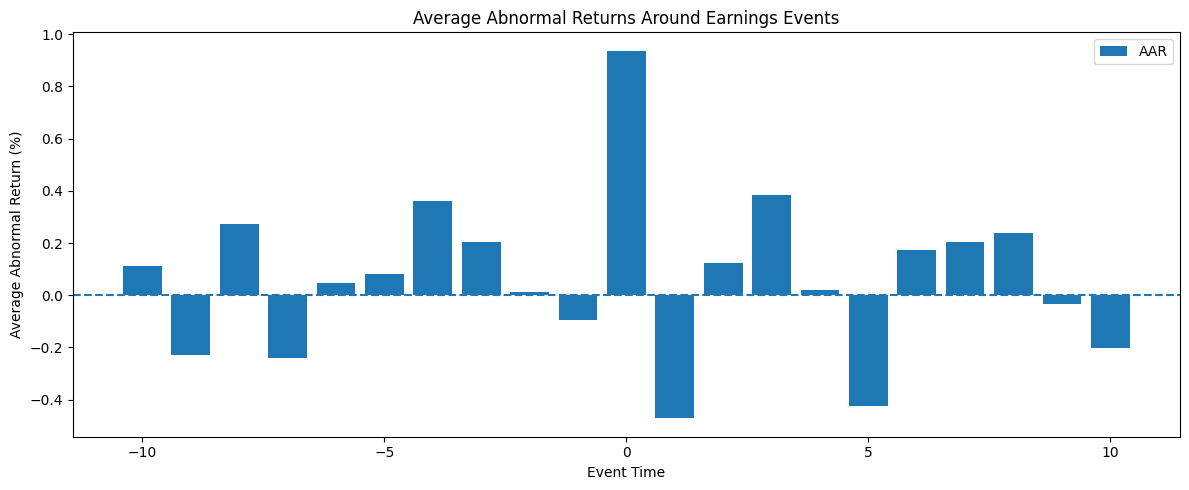

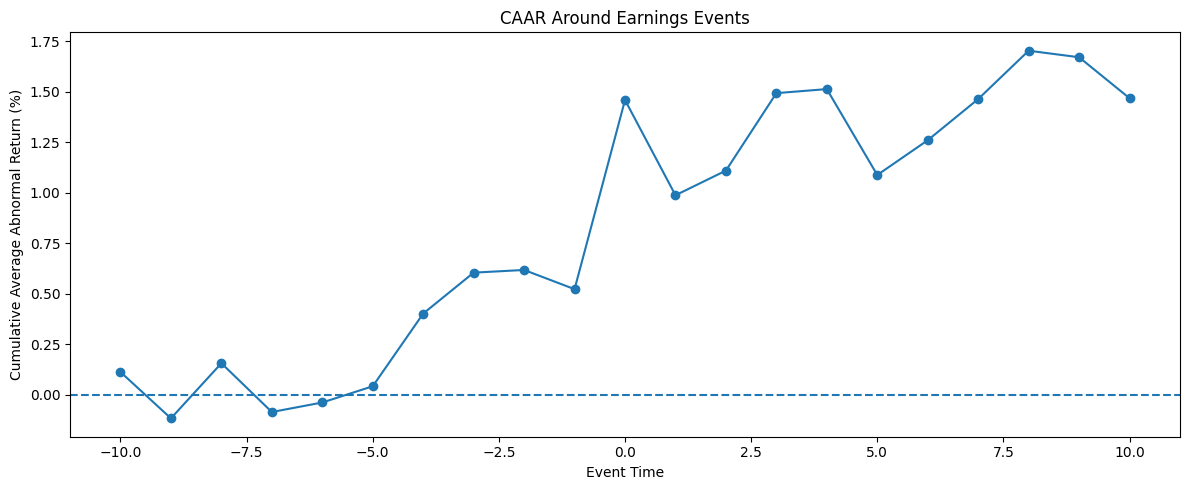

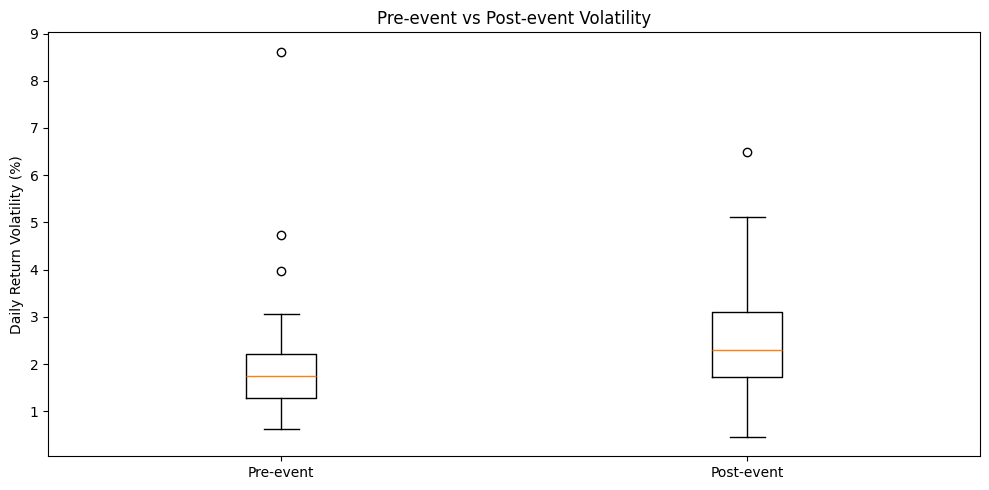


All plots and validation report saved successfully.


In [27]:

# Final robustness checks and visualisations

# 1. Structural validation
checks = {
    "52 eligible events analysed": len(expanded_car_df) == 52,
    "52 market models fitted": len(market_model_df) == 52,
    "1092 abnormal return rows": len(expanded_ar_df) == 1092,
    "21 event-time observations": len(aar_results) == 21,
    "52 volatility records": len(expanded_volatility_df) == 52,
    "No duplicate event IDs": expanded_car_df["event_id"].is_unique,
    "No missing CAR values": expanded_car_df["CAR"].notna().all(),
    "No missing volatility values": expanded_volatility_df[
        ["pre_volatility", "post_volatility"]
    ].notna().all().all()
}

validation_df = pd.DataFrame(
    [{"check": k, "passed": v} for k, v in checks.items()]
)

print("FINAL VALIDATION")
display(validation_df)

print("\nPassed:", validation_df["passed"].sum(), "/", len(checks))

# 2. AAR and CAAR plot
plt.figure(figsize=(12, 5))
plt.bar(
    aar_results["event_time"],
    aar_results["AAR"],
    label="AAR"
)
plt.axhline(0, linestyle="--")
plt.xlabel("Event Time")
plt.ylabel("Average Abnormal Return (%)")
plt.title("Average Abnormal Returns Around Earnings Events")
plt.legend()
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "expanded_aar_plot.png",
    dpi=300
)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(
    aar_results["event_time"],
    aar_results["CAAR"],
    marker="o"
)
plt.axhline(0, linestyle="--")
plt.xlabel("Event Time")
plt.ylabel("Cumulative Average Abnormal Return (%)")
plt.title("CAAR Around Earnings Events")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "expanded_caar_plot.png",
    dpi=300
)
plt.show()

# 3. Pre vs post volatility plot
plt.figure(figsize=(10, 5))
plt.boxplot(
    [
        expanded_volatility_df["pre_volatility"],
        expanded_volatility_df["post_volatility"]
    ],
    tick_labels=["Pre-event", "Post-event"]
)
plt.ylabel("Daily Return Volatility (%)")
plt.title("Pre-event vs Post-event Volatility")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "expanded_volatility_comparison.png",
    dpi=300
)
plt.show()

# Save validation report
validation_df.to_csv(
    RESULTS_DIR / "expanded_validation_report.csv",
    index=False
)

print("\nAll plots and validation report saved successfully.")


# Conclusion – Dataset Expansion and Robustness Analysis

This notebook expanded the original event study from 8 events across 3 companies to 61 collected event records across 8 companies. After applying the required estimation and event-window conditions, 52 events were considered eligible for quantitative analysis.

A market model was fitted separately for each eligible event using the S&P 500 as the benchmark. The analysis generated 1,092 abnormal-return observations and 52 cumulative abnormal return (CAR) values.

The average CAR across all events was +1.4672%. However, the overall t-test (p = 0.2450) and Wilcoxon test (p = 0.3529) did not indicate statistically significant abnormal returns. Similarly, none of the four tested event windows showed statistically significant CAR results at the 5% significance level.

In contrast, volatility analysis showed an increase in average daily return volatility from 1.9291% before the events to 2.4733% after the events. The paired t-test (p = 0.0127) and Wilcoxon test (p = 0.0014) indicated a statistically significant increase in post-event volatility.

The findings suggest that earnings announcements in this sample were associated with increased market uncertainty or price variability, while evidence of a consistent abnormal-return effect was insufficient.

## Limitations

1. The analysis covers only eight companies and 52 eligible events.
2. Some candidate events were excluded because sufficient estimation or event-window observations were unavailable.
3. Event announcement timing was not independently verified for every company and event. Reaction dates for some candidates remain provisional.
4. Earnings announcements may coincide with other corporate or macroeconomic developments.
5. Cross-company event observations may be exposed to common market shocks, so statistical independence cannot be assumed.
6. The analysis uses a single market benchmark and a market-model specification.
7. Statistical association does not establish causality or guarantee an executable trading strategy.

## Future Improvements

- Verify exact announcement timestamps and reaction dates for all events.
- Expand the dataset to more companies, sectors, and event categories.
- Apply alternative expected-return models and benchmarks.
- Use cross-sectional dependence-robust statistical methods.
- Investigate event-level sentiment and its relationship with CAR.
- Evaluate trading strategies with transaction costs and out-of-sample testing.

## Final Conclusion

The expanded analysis demonstrates that event-study methodology can be applied across multiple companies to examine abnormal returns and volatility changes. While the sample does not provide statistically significant evidence of average abnormal returns, it reveals a statistically significant increase in post-event volatility. These findings provide a useful foundation for further quantitative event analysis.